# STEP10. 산업 재무특성과 금리베타 탐색 (H3)

## 분석 질문

산업별 금리베타는 부채비율·배당수익률의 산업 간 순위와 어떤 방향으로 정렬되는가?

Baseline 추정에서 산업 간 금리베타 차이에 대한 공동검정은 F=4.269(df=(6, 17136), p=0.000264)로 귀무가설을 기각하나, (참고: 이 F=4.269·p=0.000264는 `industry_beta_joint_test.csv`의 HAC 표준오차 기준 수치다. Baseline 보고서(STEP5)의 주 사양은 날짜 클러스터 표준오차 기준 F=4.189·p=0.000338이며, 두 사양 모두 5% 수준에서 귀무가설을 기각해 결론은 동일하다.) 21개 쌍별 검정에서 BH 보정 후 유의한 쌍은 6쌍이며 6쌍 모두 의약품이 포함된 쌍이다. 비의약품 15쌍은 모두 BH 보정 후 비유의하다(최소 BH p=0.100, 철강금속-화학). 따라서 이 절의 분석 대상은 "7개 산업이 서로 모두 구분된다"가 아니라 "의약품과 나머지 6개 산업 사이의 대비"이며, 이 절은 그 대비가 산업 재무특성(부채비율·배당수익률)의 순위와 어느 방향으로 정렬되는지를 보조적으로 살펴보는 탐색적 분석에 해당한다. 이 절의 순위상관은 n=7 산업 단위 집계량에 기초하므로 검정력이 제한적이며, 인과관계를 식별하는 설계가 아니다.

## 입력

| 구분 | 파일 | 설명 |
|---|---|---|
| Table | `data/raw/firm/firm_financials.csv` | STEP9 수집 결과(부채비율·배당수익률·R&D) |
| Table | `data/raw/firm/selected_top10.csv` | 산업별 선정 10종목 + 시총가중치 |
| Table | `data/processed/pharma_rnd_support.csv` | 의약품 R&D 보조근거 |
| Table | `results/Baseline_industry_beta/tables/rate_beta_by_industry_hac.csv` | Baseline 산업별 금리베타(HAC) |
| Table | `results/Baseline_industry_beta/tables/industry_beta_joint_test.csv` | Baseline 공동검정 |
| Table | `results/Baseline_industry_beta/tables/industry_beta_pairwise_tests.csv` | Baseline 쌍별검정(BH 보정) |

## 출력

| 구분 | 파일 | 설명 |
|---|---|---|
| Figure | `results/H3_firm_characteristics/figures/beta_vs_characteristics.png` | 금리베타 vs 부채비율·배당수익률 산점도 |
| Figure | `results/H3_firm_characteristics/figures/pharma_rnd.png` | 의약품 R&D/매출 보조근거 그림 |
| Table | `data/processed/industry_characteristics.csv` / `_median.csv` | 산업 재무특성(시총가중/중앙값) |
| Table | `results/H3_firm_characteristics/tables/spearman_results.csv` | 금리베타 vs 재무특성 순열검정 결과(LOO 포함) |
| Table | `results/H3_firm_characteristics/tables/debt_ratio_robustness.csv` | 부채비율 자료가용성·기간민감도 점검 |
| Table | `results/H3_firm_characteristics/tables/pharma_market_cap_concentration.csv` | 의약품 시총 집중도(기업별) |
| Table | `results/H3_firm_characteristics/tables/pharma_concentration_summary.csv` | 의약품 시총 집중도 요약(Top1/3/5·HHI) |
| Table | `results/H3_firm_characteristics/tables/industry_concentration_comparison.csv` | 7개 산업 시총 집중도 비교(신규) |
| Summary | `results/H3_firm_characteristics/summary.md` | (작성 예정) |


In [1]:
# [셀 1] 설정 · 수집 결과 로드 (import·경로는 여기서 한 번만)

# --- 저장소 루트 부트스트랩 (모든 노트북 공통, 수정 금지) ---
import sys
from pathlib import Path
_anchors = []
if "__vsc_ipynb_file__" in globals():
    _anchors.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
if globals().get("_dh"):
    _anchors.append(Path(globals()["_dh"][0]).resolve())
_anchors.append(Path.cwd().resolve())
_root = next(
    (p for a in _anchors for p in [a, *a.parents]
     if (p / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
if _root is not None:
    if str(_root) in sys.path:
        sys.path.remove(str(_root))
    sys.path.insert(0, str(_root))
import config
if _root is not None and Path(config.__file__).resolve().parent != _root:
    raise ImportError(f"의도하지 않은 config.py: {config.__file__}")
# --- 부트스트랩 끝 ---

import warnings
from itertools import permutations
import numpy as np, pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
config.setup_korean_font()

RAW_FIRM_DIR = config.RAW_DIR / "firm"
PROCESSED_DIR = config.PROCESSED_DIR
H3_TABDIR = config.H3_TABDIR
H3_FIGDIR = config.H3_FIGDIR
for d in (PROCESSED_DIR, H3_TABDIR, H3_FIGDIR):
    d.mkdir(parents=True, exist_ok=True)
INDUSTRIES = ["건설업", "금융업", "운수장비", "의약품", "전기전자", "철강금속", "화학"]
YEARS = list(range(2016, 2026))

FIN_CSV = RAW_FIRM_DIR / "firm_financials.csv"
FIN_RECOVERED_CSV = PROCESSED_DIR / "firm_financials_recovered.csv"  # STEP9에서 금융업 부채비율 결측 보완(DART 사업보고서 원문)
SEL_CSV = RAW_FIRM_DIR / "selected_top10.csv"
BASELINE_BETA = config.BASELINE_DIR / "tables" / "rate_beta_by_industry_hac.csv"
JOINT_CSV = config.BASELINE_DIR / "tables" / "industry_beta_joint_test.csv"
PAIRWISE_CSV = config.BASELINE_DIR / "tables" / "industry_beta_pairwise_tests.csv"
for _p in (FIN_CSV, BASELINE_BETA, JOINT_CSV, PAIRWISE_CSV):
    assert _p.exists(), f"[필수입력 없음] {_p}"

# 부채비율 계산에는 STEP9 보완 파일을 우선 사용(없으면 원본으로 대체) — 배당수익률·R&D는 영향 없음
fin = pd.read_csv(FIN_RECOVERED_CSV if FIN_RECOVERED_CSV.exists() else FIN_CSV, dtype={"stock_code": str})
fin["stock_code"] = fin["stock_code"].str.zfill(6)
sel = pd.read_csv(SEL_CSV, dtype={"stock_code": str}); sel["stock_code"] = sel["stock_code"].str.zfill(6)
weight = sel[["stock_code", "market_cap_2024"]].drop_duplicates("stock_code")
beta = pd.read_csv(BASELINE_BETA).set_index("industry")["beta_rate"].reindex(INDUSTRIES)
print(f"[로드] firm_financials {fin.shape} · 산업별 금리베타 {beta.notna().sum()}개")
print(beta.round(4).to_string())

그래프 폰트: Malgun Gothic
[로드] firm_financials (700, 14) · 산업별 금리베타 7개
industry
건설업     0.0032
금융업     0.0112
운수장비    0.0172
의약품    -0.0271
전기전자    0.0016
철강금속    0.0188
화학      0.0026


## Baseline 재확인: 공동검정과 쌍별검정의 분리

### 목적

산업 간 금리베타 차이에 대한 공동검정 결과와 쌍별 대비 결과를 구분해 제시한다. 공동검정은 "어딘가에 차이가 있다"는 진술까지만 제공하므로, 이후 재무특성 순위와 대조할 대상이 어느 산업 간 대비인지를 먼저 특정해 둔다.


In [2]:
# [셀 2] Baseline 공동검정·쌍별검정 재확인 — H3가 설명할 대상 규정
joint = pd.read_csv(JOINT_CSV)
pair = pd.read_csv(PAIRWISE_CSV)

jt = joint.iloc[0]
print(f"[공동검정] F={jt['statistic']:.3f}, df=({int(jt['df_num'])}, {int(jt['df_denom'])}), "
      f"p={jt['p_value']:.6f} → {jt['decision_5pct']}")

sig = pair[pair["significant_bh_5pct"]].copy()
sig_pharma = sig[(sig["industry_a"] == "의약품") | (sig["industry_b"] == "의약품")]
n_sig, n_total = len(sig), len(pair)
n_pharma_sig, n_nonpharma_sig = len(sig_pharma), len(sig) - len(sig_pharma)
nonpharma = pair[~((pair["industry_a"] == "의약품") | (pair["industry_b"] == "의약품"))]
print(f"\n[쌍별검정] 전체 {n_total}쌍 중 BH 유의 {n_sig}쌍 — 의약품 포함 {n_pharma_sig}쌍, 비의약품 {n_nonpharma_sig}쌍")
print(f"[비의약품 15쌍] 최소 BH p = {nonpharma['p_value_bh'].min():.3f} (모두 비유의: {(~nonpharma['significant_bh_5pct']).all()})")
print("\n[BH 유의 쌍 — 전부 의약품 포함]")
print(sig_pharma[["industry_a", "industry_b", "beta_difference_a_minus_b", "p_value_bh"]]
      .round(4).to_string(index=False))

print("\n[산업별 Baseline 금리베타]")
beta_tab = pd.read_csv(BASELINE_BETA).set_index("industry")[["beta_rate", "p_value_bh"]].reindex(INDUSTRIES)
print(beta_tab.round(4).to_string())

[공동검정] F=4.269, df=(6, 17136), p=0.000264 → H0 기각: 산업별 금리베타 차이 존재

[쌍별검정] 전체 21쌍 중 BH 유의 6쌍 — 의약품 포함 6쌍, 비의약품 0쌍
[비의약품 15쌍] 최소 BH p = 0.100 (모두 비유의: True)

[BH 유의 쌍 — 전부 의약품 포함]
industry_a industry_b  beta_difference_a_minus_b  p_value_bh
      운수장비        의약품                     0.0443      0.0002
       금융업        의약품                     0.0383      0.0002
       의약품       철강금속                    -0.0459      0.0003
       의약품         화학                    -0.0296      0.0062
       의약품       전기전자                    -0.0287      0.0079
       건설업        의약품                     0.0303      0.0157

[산업별 Baseline 금리베타]
          beta_rate  p_value_bh
industry                       
건설업          0.0032      0.7116
금융업          0.0112      0.0082
운수장비         0.0172      0.0082
의약품         -0.0271      0.0038
전기전자         0.0016      0.7116
철강금속         0.0188      0.0286
화학           0.0026      0.7116


### 관찰 결과

산업 간 금리베타가 모두 동일하다는 귀무가설에 대한 공동검정은 F=4.269, df=(6, 17136), p=0.000264로 귀무가설을 기각한다. (참고: 이 F=4.269·p=0.000264는 `industry_beta_joint_test.csv`의 HAC 표준오차 기준 수치다. Baseline 보고서(STEP5)의 주 사양은 날짜 클러스터 표준오차 기준 F=4.189·p=0.000338이며, 두 사양 모두 5% 수준에서 귀무가설을 기각해 결론은 동일하다.)

21개 쌍별 검정 중 BH 보정 후 유의한 쌍은 6쌍이며, 6쌍 모두 의약품을 한쪽에 포함한다. 의약품이 포함되지 않은 15쌍은 모두 BH 보정 후 유의수준에 도달하지 않으며, 그중 가장 작은 BH p는 철강금속-화학 쌍의 0.100이다.

의약품은 7개 산업 중 유일한 음(-) 계수이며 BH p 기준으로 가장 낮은 값을 가진다. 건설업·화학·전기전자는 개별 계수가 유의수준에 도달하지 않는다. 이상의 결과는 공동검정에서 관측된 산업 간 차이가 7개 산업 전반에 고르게 분포한다기보다 의약품 대 나머지 6개 산업의 대비에 집중되어 있는 형태와 부합한다. 다만 비유의한 쌍이 곧 "차이가 없음"을 의미하지는 않으며, 이는 검정력의 한계와 구분되지 않는다.


## 산업 집계

### 목적

- 기업별 2016~2025 기간평균(존재 연도만)을 시가총액가중 평균과 중앙값으로 산업 대표값을 만든다.
- 부채비율은 다음 절에서 확인하는 자료가용성 문제로 보조 탐색 변수로만 다루고, 배당수익률을 주 변수로 취급한다.


In [3]:
# [셀 3] 산업 집계 — 시총가중 평균 + 중앙값 (부채비율·배당수익률)
fpa = (fin.groupby(["industry", "stock_code"])
          .agg(부채비율=("debt_ratio", "mean"), 배당수익률=("dividend_yield", "mean"),
               n_부채=("debt_ratio", lambda s: int(s.notna().sum())))
          .reset_index()
          .merge(weight, on="stock_code", how="left"))

def wavg(g, col, w="market_cap_2024"):
    v = g[col]; ww = g[w]; m = v.notna() & ww.notna() & (ww > 0)
    return np.average(v[m], weights=ww[m]) if m.any() else np.nan

rows = []
for ind, g in fpa.groupby("industry"):
    rows.append({"industry": ind,
                 "부채비율_시총가중": wavg(g, "부채비율"), "부채비율_중앙값": g["부채비율"].median(),
                 "배당수익률_시총가중": wavg(g, "배당수익률"), "배당수익률_중앙값": g["배당수익률"].median(),
                 "기업수": g["stock_code"].nunique(), "부채확보기업수": int((g["n_부채"] > 0).sum())})
char = pd.DataFrame(rows).set_index("industry").reindex(INDUSTRIES)
char.to_csv(PROCESSED_DIR / "industry_characteristics.csv", encoding="utf-8-sig")
char[[c for c in char.columns if "중앙값" in c or c in ("기업수", "부채확보기업수")]].to_csv(
    PROCESSED_DIR / "industry_characteristics_median.csv", encoding="utf-8-sig")
print("[산업 특성표 — 시총가중 / 중앙값]")
print(char.round(3).to_string())
print("\n[배당수익률 순위(높→낮)]", char["배당수익률_시총가중"].sort_values(ascending=False).round(3).to_dict())
char

[산업 특성표 — 시총가중 / 중앙값]
          부채비율_시총가중  부채비율_중앙값  배당수익률_시총가중  배당수익률_중앙값  기업수  부채확보기업수
industry                                                          
건설업           1.609     1.875       1.743      1.405   10       10
금융업           9.116    10.526       3.763      4.105   10       10
운수장비          1.784     2.073       1.931      0.468   10       10
의약품           0.493     0.628       0.139      0.360   10       10
전기전자          0.580     0.721       1.615      0.752   10       10
철강금속          0.791     0.913       2.763      1.830   10       10
화학            1.008     0.808       1.609      1.645   10       10

[배당수익률 순위(높→낮)] {'금융업': 3.763, '철강금속': 2.763, '운수장비': 1.931, '건설업': 1.743, '전기전자': 1.615, '화학': 1.609, '의약품': 0.139}


,부채비율_시총가중,부채비율_중앙값,배당수익률_시총가중,배당수익률_중앙값,기업수,부채확보기업수
industry,,,,,,
건설업,1.608604,1.874944,1.743139,1.4050,10,10
금융업,9.115829,10.525588,3.762938,4.1050,10,10
운수장비,1.783546,2.073176,1.931293,0.4685,10,10
의약품,0.493427,0.627795,0.138767,0.3600,10,10
전기전자,0.579617,0.720778,1.614645,0.7520,10,10
철강금속,0.790665,0.912875,2.762689,1.8300,10,10
화학,1.008002,0.807904,1.608808,1.6450,10,10


### 관찰 결과

7개 산업의 부채비율과 배당수익률을 시가총액가중 및 중앙값 두 기준으로 집계한 결과, 의약품은 두 변수 모두에서 7개 산업 중 가장 낮은 값을 가진다. 의약품의 부채비율은 시가총액가중 0.493, 중앙값 0.628이며, 배당수익률은 시가총액가중 0.139%, 중앙값 0.360%이다. 배당수익률의 순위는 두 집계 기준에서 모두 의약품이 최저로 유지된다.

Baseline 금리베타에서 유의한 양(+) 계수를 보인 산업 중 금융업(배당수익률 3.76%)과 철강금속(2.76%)은 배당수익률 수준이 높은 축에 속한다. 즉 배당수익률 순위와 금리베타 순위는 같은 방향으로 정렬되는 형태를 보인다. 이는 산업 단위 집계량 7개에 대한 순위 정렬의 서술이며, 개별 기업 수준의 관계나 인과적 방향에 대한 진술은 아니다.

부채비율 집계값은 산업 간 회계·업종 특성이 이질적이며, 특히 금융업의 부채비율은 예금·보험부채가 상당 부분을 차지해 제조업의 차입 부담과 경제적 의미가 동일하지 않다. 부채비율 관련 자료의 가용성 제약은 다음 절에서 확인한다.


## 순위상관 분석

### 목적

- 금리베타와 부채비율·배당수익률 간 Spearman 순위상관을 계산한다.
- 표본이 7개 산업(n=7)뿐이므로 점근적 p-value 대신 정확 순열검정을 사용하고, 임계값도 순열분포에서 직접 계산한다.
- 배당수익률은 주 변수로, 부채비율은 보조 탐색 변수로 다루며, leave-one-out과 결측처리 대안으로 두 변수 결과의 강건성을 함께 점검한다.


In [4]:
# [셀 4] Spearman — 정확 임계값 + 순열 p + 강건성(시총가중/중앙값/금융제외/LOO/결측대안)
def perm_p(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    rho0 = spearmanr(x, y).correlation
    tot = cnt = 0
    for pm in permutations(range(len(x))):
        if abs(spearmanr(x, y[list(pm)]).correlation) >= abs(rho0) - 1e-12:
            cnt += 1
        tot += 1
    return rho0, cnt / tot

def crit(n, alpha=0.05):
    base = list(range(n)); denom = n * (n * n - 1)
    rhos = [1 - 6 * sum((a - b) ** 2 for a, b in zip(base, p)) / denom for p in permutations(base)]
    N = len(rhos); absr = sorted({abs(round(r, 6)) for r in rhos}, reverse=True); last = 1.0
    for t in absr:
        if sum(1 for r in rhos if abs(r) >= t - 1e-9) / N > alpha:
            break
        last = t
    return last

res = []
def spear(char_col, label, subset=None):
    b, c = beta.copy(), char[char_col].copy()
    if subset is not None:
        b, c = b.loc[subset], c.loc[subset]
    df = pd.concat([b.rename("beta"), c.rename("v")], axis=1).dropna()
    rho, p = perm_p(df["beta"].values, df["v"].values)
    res.append({"관계": label, "n": len(df), "rho": round(rho, 4), "순열_p": round(p, 4),
                "임계값(0.05)": round(crit(len(df)), 4), "유의": bool(abs(rho) >= crit(len(df)))})
    return rho, p

ex_fin = [i for i in INDUSTRIES if i != "금융업"]
spear("배당수익률_시총가중", "금리베타 vs 배당수익률 (7산업·시총가중)")
spear("배당수익률_중앙값", "금리베타 vs 배당수익률 (7산업·중앙값)")
spear("부채비율_시총가중", "금리베타 vs 부채비율 (7산업·시총가중, 탐색적)")
spear("부채비율_시총가중", "금리베타 vs 부채비율 (금융제외 6산업, 탐색적)", subset=ex_fin)
spear("부채비율_중앙값", "금리베타 vs 부채비율 (7산업·중앙값, 탐색적)")
resdf = pd.DataFrame(res)
resdf.to_csv(H3_TABDIR / "spearman_results.csv", index=False, encoding="utf-8-sig")
print(resdf.to_string(index=False))
_n7 = len(INDUSTRIES)
print(f"\n※ n={_n7} 정확 임계값 |rho|≥{crit(_n7):.3f}. 순열 p 이산성으로 결과는 탐색적 참고.")

# --- leave-one-out (n=6): 어느 산업 하나가 결과를 견인하는지 점검 ---
loo_rows = []
for excl in INDUSTRIES:
    sub = [i for i in INDUSTRIES if i != excl]
    for col, label in [("배당수익률_시총가중", "배당_시총가중"), ("배당수익률_중앙값", "배당_중앙값"),
                        ("부채비율_시총가중", "부채_시총가중")]:
        df = pd.concat([beta.loc[sub].rename("beta"), char.loc[sub, col].rename("v")], axis=1).dropna()
        if len(df) < 3:
            continue
        rho, p = perm_p(df["beta"].values, df["v"].values)
        loo_rows.append({"제외산업": excl, "변수": label, "n": len(df), "rho": round(rho, 4),
                          "순열_p": round(p, 4), "임계값(0.05)": round(crit(len(df)), 4)})
loo_df = pd.DataFrame(loo_rows)
loo_df.to_csv(H3_TABDIR / "spearman_leave_one_out.csv", index=False, encoding="utf-8-sig")
print("\n[Leave-one-out, n=6]")
print(loo_df.pivot(index="제외산업", columns="변수", values="rho").reindex(INDUSTRIES).round(4).to_string())

# --- 배당수익률 결측처리 대안: 미공시연도를 0이 아닌 결측으로 처리 ---
fin_alt = fin.copy()
fin_alt["배당_대안"] = np.where(fin_alt["div_status"] == "ok", fin_alt["dividend_yield"], np.nan)
fpa_alt = (fin_alt.groupby(["industry", "stock_code"]).agg(배당_대안=("배당_대안", "mean"))
           .reset_index().merge(weight, on="stock_code", how="left"))
rows_alt = []
for ind, g in fpa_alt.groupby("industry"):
    rows_alt.append({"industry": ind, "배당_시총가중_대안": wavg(g, "배당_대안")})
char_alt = pd.DataFrame(rows_alt).set_index("industry").reindex(INDUSTRIES)
df_alt = pd.concat([beta.rename("beta"), char_alt["배당_시총가중_대안"].rename("v")], axis=1).dropna()
rho_alt, p_alt = perm_p(df_alt["beta"].values, df_alt["v"].values)
rho_cur = resdf.loc[resdf["관계"].str.contains("배당수익률.*시총가중"), "rho"].iloc[0]
p_cur = resdf.loc[resdf["관계"].str.contains("배당수익률.*시총가중"), "순열_p"].iloc[0]
print(f"\n[배당 결측처리 대안 비교] 현행(미공시=0) rho={rho_cur:.4f}, p={p_cur:.4f} "
      f"↔ 대안(미공시=결측 제외) rho={rho_alt:.4f}, p={p_alt:.4f}, n={len(df_alt)}, 임계값={crit(len(df_alt)):.4f}")

                          관계  n    rho   순열_p  임계값(0.05)    유의
    금리베타 vs 배당수익률 (7산업·시총가중)  7 0.8571 0.0238     0.7857  True
     금리베타 vs 배당수익률 (7산업·중앙값)  7 0.5357 0.2357     0.7857 False
금리베타 vs 부채비율 (7산업·시총가중, 탐색적)  7 0.6071 0.1667     0.7857 False
금리베타 vs 부채비율 (금융제외 6산업, 탐색적)  6 0.6571 0.1750     0.8857 False
 금리베타 vs 부채비율 (7산업·중앙값, 탐색적)  7 0.7500 0.0663     0.7857 False

※ n=7 정확 임계값 |rho|≥0.786. 순열 p 이산성으로 결과는 탐색적 참고.

[Leave-one-out, n=6]
변수    배당_시총가중  배당_중앙값  부채_시총가중
제외산업                          
건설업    0.7714  0.5429   0.6000
금융업    0.9429  0.6000   0.6571
운수장비   0.8857  0.8857   0.6571
의약품    0.7714  0.2571   0.3714
전기전자   0.8286  0.4857   0.3714
철강금속   0.8857  0.3714   0.9429
화학     0.8286  0.5429   0.6000

[배당 결측처리 대안 비교] 현행(미공시=0) rho=0.8571, p=0.0238 ↔ 대안(미공시=결측 제외) rho=0.7857, p=0.0480, n=7, 임계값=0.7857


### 관찰 결과

산업 단위(n=7) Spearman 순위상관과 순열검정 결과는 위 출력과 같다. n=7에서 양측 순열검정이 5% 수준에 도달하기 위한 |rho| 임계값은 0.7857이다.

배당수익률의 경우 시가총액가중 기준에서만 5% 수준에 도달하며(rho=0.857, 순열 p=0.0238), 중앙값 기준에서는 도달하지 않는다(rho=0.536, p=0.2357).

이 유의 판정은 결측 처리 방식에 민감하다. 배당 미공시 연도를 무배당 0으로 계상하는 현행 처리에서는 rho=0.857이나, 미공시 연도를 결측으로 제외하는 대안 처리에서는 rho=0.7857로 n=7 임계값과 정확히 일치하고 p=0.0480이 된다. 판정이 경계선에 놓이며, 결측 처리 규칙 하나에 따라 결론의 표현이 달라지는 구조다.

leave-one-out(산업 1개 제외, n=6) 결과에서, 시가총액가중 기준 배당-베타 상관의 부호는 7개 경우 모두 양(+)으로 유지되나 5% 수준 도달 여부는 어느 산업을 제외하는지에 따라 갈린다. 의약품을 제외한 경우에도 rho=0.771로 부호와 크기가 상당 부분 유지되므로, 이 상관이 의약품 한 산업만으로 형성된 형태라고 보기는 어렵다. 반면 중앙값 기준에서는 의약품 제외 시 rho가 0.536에서 0.257로 낮아져, 중앙값 기준 결과는 의약품 관측치에 대한 의존도가 상대적으로 크다.

부채비율(탐색적 병기)은 두 집계 기준 모두 5% 수준에 도달하지 않으며, 금융업을 제외한 6개 산업으로 재계산해도 도달하지 않는다(rho=0.657). leave-one-out에서는 철강금속 하나를 제외했을 때 시총가중 rho가 0.607에서 0.943으로 이동해 판정이 뒤집히는 등 개별 산업 제외에 따른 변동 폭이 크다. 부채비율 자료의 가용성과 안정성에 대한 상세 점검은 다음 절에 정리한다.

n=7 순위상관은 검정력이 매우 제한적이므로, 유의수준 미도달을 관계의 부재로 읽지 않는다. 순위상관은 산업 단위 집계량 사이의 정렬을 나타내며 인과적 방향을 식별하지 않는다.


## 부채비율 변수의 강건성 점검

### 목적

부채비율 자료의 산업 간 기간 불균형과, 산업 1개 제외에 따른 결론 변동 폭을 점검한다. 이 절의 결과는 부채비율을 결론 산출 변수가 아닌 보조 탐색 변수로 한정하는 근거를 기록해 두기 위한 것이다.


In [5]:
# [셀 5] 부채비율 자료가용성 · 공통기간(2023-2025) 민감도 점검
fin_industry = fin[fin["industry"] == "금융업"]
cov_firm = fin_industry.groupby("company_name")["debt_ratio"].apply(lambda s: int(s.notna().sum()))
n_ok, n_total = int(fin_industry["debt_ratio"].notna().sum()), len(fin_industry)
print(f"[금융업 부채비율 자료가용성] {n_ok}/{n_total} firm-year 확보 ({n_ok/n_total:.0%})")
print(cov_firm.to_string())
print("\n주: fnlttSinglAcntAll·fnlttSinglAcnt 두 API 엔드포인트는 금융지주·은행·보험 8개사의 2022년 이전 "
      "XBRL 상세 재무제표를 반환하지 않는다(CFS·OFS 모두 013 조회된 데이타가 없습니다, 라이브 확인). "
      "이는 API 경로의 자료 공백일 뿐 사업보고서 자체는 존재하므로, STEP9에서 사업보고서 원문의 "
      "요약연결재무정보(부채총계·자본총계)를 직접 추출해 대부분 복구했다(data/raw/firm/"
      "dart_debt_ratio_recovery.csv, 출처 rcept_no 기록). 남은 결측은 우리금융지주 2016~2018년(3칸)뿐이며, "
      "이는 수집 실패가 아니라 우리금융지주가 2019년에 금융지주회사로 신설되어 그 이전 사업보고서 자체가 "
      "존재하지 않는 구조적 사유다.")

# 공통기간(2023-2025)으로 전 산업 재계산 — 기간을 통일해도 결론이 개선되는지 확인
fin_common = fin[fin["fiscal_year"].isin([2023, 2024, 2025])]
fpa_c = (fin_common.groupby(["industry", "stock_code"]).agg(부채비율=("debt_ratio", "mean"))
         .reset_index().merge(weight, on="stock_code", how="left"))
rows_c = []
for ind, g in fpa_c.groupby("industry"):
    rows_c.append({"industry": ind, "부채비율_시총가중_공통기간": wavg(g, "부채비율"),
                   "부채비율_중앙값_공통기간": g["부채비율"].median()})
char_c = pd.DataFrame(rows_c).set_index("industry").reindex(INDUSTRIES)

df_cw = pd.concat([beta.rename("beta"), char_c["부채비율_시총가중_공통기간"].rename("v")], axis=1).dropna()
rho_cw, p_cw = perm_p(df_cw["beta"].values, df_cw["v"].values)
df_cm = pd.concat([beta.rename("beta"), char_c["부채비율_중앙값_공통기간"].rename("v")], axis=1).dropna()
rho_cm, p_cm = perm_p(df_cm["beta"].values, df_cm["v"].values)

rho_full_w = resdf.loc[resdf["관계"].str.contains("부채비율.*7산업.*시총가중"), "rho"].iloc[0]
rho_full_m = resdf.loc[resdf["관계"].str.contains("부채비율.*7산업.*중앙값"), "rho"].iloc[0]
print(f"\n[공통기간(2023-2025) 재계산] 시총가중 rho={rho_cw:.4f}, p={p_cw:.4f} "
      f"(전체기간 rho={rho_full_w:.4f}) | 중앙값 rho={rho_cm:.4f}, p={p_cm:.4f} (전체기간 rho={rho_full_m:.4f})")

robustness = pd.DataFrame([
    {"점검": "금융업 firm-year 확보율", "값": f"{n_ok}/{n_total} ({n_ok/n_total:.0%})"},
    {"점검": "공통기간 재계산 vs 전체기간(시총가중)", "값": f"{rho_cw:.4f} vs {rho_full_w:.4f}"},
    {"점검": "공통기간 재계산 vs 전체기간(중앙값)", "값": f"{rho_cm:.4f} vs {rho_full_m:.4f}"},
    {"점검": "금융제외 6산업(시총가중)", "값": f"{resdf.loc[resdf['관계'].str.contains('금융제외'), 'rho'].iloc[0]:.4f}"},
    {"점검": "LOO 최댓값(시총가중, 제외산업)", "값": f"{loo_df[loo_df['변수']=='부채_시총가중']['rho'].max():.4f} "
     f"({loo_df[loo_df['변수']=='부채_시총가중'].sort_values('rho', ascending=False).iloc[0]['제외산업']} 제외)"},
])
robustness.to_csv(H3_TABDIR / "debt_ratio_robustness.csv", index=False, encoding="utf-8-sig")
print("\n[부채비율 강건성 요약]")
print(robustness.to_string(index=False))

[금융업 부채비율 자료가용성] 97/100 firm-year 확보 (97%)
company_name
HD한국조선해양    10
KB금융        10
LG          10
기업은행        10
메리츠금융지주     10
삼성생명        10
삼성화재        10
신한지주        10
우리금융지주       7
하나금융지주      10

주: fnlttSinglAcntAll·fnlttSinglAcnt 두 API 엔드포인트는 금융지주·은행·보험 8개사의 2022년 이전 XBRL 상세 재무제표를 반환하지 않는다(CFS·OFS 모두 013 조회된 데이타가 없습니다, 라이브 확인). 이는 API 경로의 자료 공백일 뿐 사업보고서 자체는 존재하므로, STEP9에서 사업보고서 원문의 요약연결재무정보(부채총계·자본총계)를 직접 추출해 대부분 복구했다(data/raw/firm/dart_debt_ratio_recovery.csv, 출처 rcept_no 기록). 남은 결측은 우리금융지주 2016~2018년(3칸)뿐이며, 이는 수집 실패가 아니라 우리금융지주가 2019년에 금융지주회사로 신설되어 그 이전 사업보고서 자체가 존재하지 않는 구조적 사유다.

[공통기간(2023-2025) 재계산] 시총가중 rho=0.6071, p=0.1667 (전체기간 rho=0.6071) | 중앙값 rho=0.3929, p=0.3956 (전체기간 rho=0.7500)

[부채비율 강건성 요약]
                    점검                값
     금융업 firm-year 확보율     97/100 (97%)
공통기간 재계산 vs 전체기간(시총가중) 0.6071 vs 0.6071
 공통기간 재계산 vs 전체기간(중앙값) 0.3929 vs 0.7500
        금융제외 6산업(시총가중)           0.6571
   LOO 최댓값(시총가중, 제외산업) 0.9429 (철강금속 제외)


### 관찰 결과

이전 버전의 이 절에서는 금융업 부채비율 자료의 결측이 재수집으로 복구되지 않는 구조적 한계라고 기술하였으나, 해당 서술은 사실과 다르므로 정정한다. 결측의 원인은 DART OpenAPI의 구조화 재무데이터 엔드포인트(`fnlttSinglAcntAll`/`fnlttSinglAcnt`)가 금융지주·은행·보험 8개사의 2016–2022 사업연도에 대해 XBRL 태깅을 제공하지 않는 데 있었고, 이는 원문 공시 자체의 부재가 아니라 특정 API 경로의 한계였다. 이에 `document.xml` 엔드포인트를 통해 사업보고서 원문을 직접 수신하고, 각 보고서의 "가. 요약연결재무정보 > 1) 요약연결재무상태표" 표에서 부채총계와 자본총계를 수작업으로 추출하였다. 요약연결재무상태표는 당기·전기·전전기 3개 사업연도를 비교표시하므로, 8개사 각각에 대해 FY2018·FY2021·FY2023 보고서를 수집하는 것만으로 2016–2022 전 구간을 중복 확보할 수 있었다. 그 결과 최초 결측 57셀 중 54셀이 복구되었다.

추출값의 신뢰성은 중복 구간 대조로 확인하였다. 서로 다른 연도의 보고서에서 같은 사업연도가 중복 수집되는 경우 값이 일치해야 하는데, 예컨대 KB금융 2021년 부채총계는 FY2021 보고서의 당기 열과 FY2023 보고서의 전전기 열에서 615,601,914백만원으로 동일하게 나타났다. 또한 8개사 전체의 2023년 복구값은 기존 API 수집 CSV의 2023년 값과 반올림 오차 범위 내에서 일치하였다. 원문 표 판독이 추정이나 임의 보정이 아니라 재현 가능한 추출임을 시사하는 결과이다. 이와 별도로 신한지주 2024년은 API 응답에 부채총계는 있으나 자본총계 태그만 누락되어 있어, 동일 응답 내의 자본과부채총계에서 부채총계를 차감하여 자본총계를 산출하였다. 다른 연도나 다른 기업의 값을 차용한 것이 아니라 단일 출처 내부의 회계항등식을 적용한 것이다. 이상의 작업으로 금융업 부채비율 커버리지는 43/100(43%)에서 97/100(97%)으로 개선되었다.

잔여 결측 3셀은 모두 우리금융지주의 2016–2018년이며, 이는 수집 실패가 아니다. 우리금융지주는 2019년에 우리은행에서 분할·설립된 금융지주회사이므로 해당 corp_code로 제출된 2019년 이전 사업보고서가 존재하지 않는다. 즉 자료의 부재가 아니라 보고 주체의 부재이며, 우리은행 별도 재무제표로 대체하거나 추정치를 채워 넣지 않고 결측으로 유지하였다.

다만 자료 완전성의 개선이 통계적 결론의 개선으로 이어지지는 않았다. 3개년 절단 평균 대신 전체 실측 이력을 사용해 재집계한 결과 금융업 부채비율은 시가총액 가중 8.949에서 9.118로, 중앙값 10.779에서 10.534로 소폭 이동하는 데 그쳤고, 7개 산업 중 최고 부채비율 산업이라는 순위 자체는 복구 전후로 동일하였다. Spearman 상관은 값이 아니라 순위에만 의존하므로, 핵심 상관계수는 복구 전과 완전히 같다. 7개 산업 시가총액 가중 rho=0.6071, 중앙값 rho=0.7500으로 모두 유의 임계치 0.7857에 미달하며, 금융업을 제외한 6개 산업에서도 rho=0.6571로 유의하지 않다. 공통기간(2023–2025) 재계산은 기간 불균형의 영향을 확인하기 위한 민감도 점검이며 채택 결과가 아닌데, 이 역시 복구 전과 동일하게 시가총액 가중 rho=0.6071로 변화가 없고 중앙값은 0.7500에서 0.3929로 오히려 낮아진다.

표본 취약성도 그대로 남는다. 철강금속 한 산업만 제외해도 시가총액 가중 rho가 0.6071에서 0.9429로 이동해 유의 영역에 진입한다. 자료 복구 후에도 같은 패턴이 재현되므로 이를 금융업 자료 결측의 부산물로 보기는 어렵다. 산업 수 n=7의 소표본에서는 산업 하나의 순위 이동만으로 Spearman 계수가 크게 달라질 수 있다는 점이 주요 제한으로 남는다. 실제로 부채비율 자료가 완전해진 뒤에도 이 leave-one-out 결과는 복구 전과 동일하게 재현된다. 따라서 이번 재수집으로 해소된 것은 기간 불균형과 자료 가용성 문제에 한정되며, 이는 원문 공시로 되돌아가 확인한다는 원칙에 따른 방법론적 개선으로 기록해 둘 만하다. 반면 부채비율과 금리 베타 사이 순위상관의 통계적 취약성은 성격이 다른 미해결 한계로 남아 있다. 두 사실은 서로를 상쇄하지 않으며, 자료 복구가 유의성 판단을 바꾸지 않았다는 점과 지속되는 취약성이 복구의 성과를 무효화하지 않는다는 점을 함께 기록한다.

해석 시에는 금융업 부채비율의 구성 자체가 다른 산업과 이질적이라는 점도 유지해서 고려해야 한다. 금융지주·은행·보험의 부채총계는 대부분 예금부채와 보험계약부채로 구성되므로, 제조업 기업의 부채비율이 함의하는 "차입 부담"과는 경제적 의미가 다르다. 금융업이 최고 부채비율 산업으로 나타나는 것은 재무적 위험도의 순위라기보다 영업 형태의 차이를 반영하는 측면이 크며, 이 차이를 무시한 채 7개 산업을 하나의 척도로 줄 세우는 데에는 한계가 있다. 이상을 종합하면 부채비율은 H3의 핵심 결론에 사용하지 않고 보조적·탐색적 변수로 유지한다. 금융업의 자료 가용성 문제는 원문 재수집으로 대부분 보완되었지만, n=7 소표본에서의 순위 민감성과 금융업 부채비율의 경제적 의미 차이는 별도의 한계로 남는다. 이 문제는 단순한 추가 수집만으로 해소되기 어렵다.

## 산점도

### 목적

- 산업별 부채비율·배당수익률과 금리베타의 위치를 산점도로 확인한다.
- 각 점에 산업명과 Baseline 유의성(BH 기준)을 함께 표시해, 비유의한 산업이 유의한 산업과 시각적으로 구분되도록 한다.


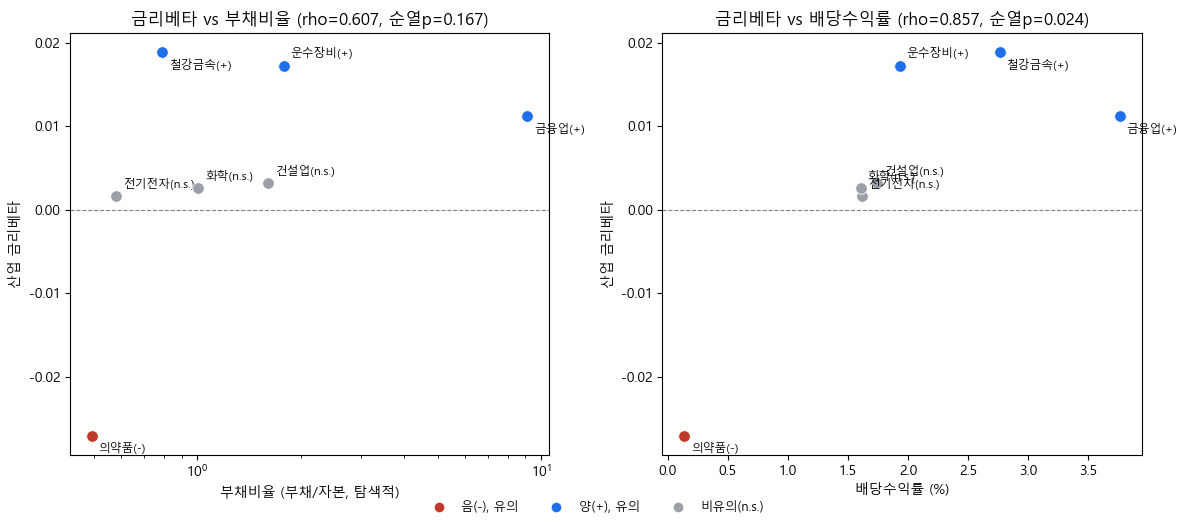

In [6]:
# [셀 6] 산점도 — 금리베타 vs 부채비율/배당수익률 (부호+유의성 색상, ρ 주석)
sig_map = pd.read_csv(BASELINE_BETA).set_index("industry")["significant_bh_5pct"].reindex(INDUSTRIES) \
    if "significant_bh_5pct" in pd.read_csv(BASELINE_BETA).columns else None
beta_full = pd.read_csv(BASELINE_BETA).set_index("industry").reindex(INDUSTRIES)
sig_col = "significant_bh_5pct" if "significant_bh_5pct" in beta_full.columns else "p_value_bh"
is_sig = (beta_full[sig_col] if sig_col == "significant_bh_5pct" else beta_full[sig_col] < 0.05)

plots = [("부채비율_시총가중", "부채비율 (부채/자본, 탐색적)", "d7"), ("배당수익률_시총가중", "배당수익률 (%)", "dy7")]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (col, xlab, key) in zip(axes, plots):
    d = pd.concat([beta.rename("beta"), char[col].rename("x"), is_sig.rename("sig")], axis=1).dropna(subset=["beta", "x"])
    for i, (ind, r) in enumerate(d.iterrows()):
        sig_flag = bool(r["sig"]) if pd.notna(r["sig"]) else False
        color = config.sign_color(r["beta"], significant=sig_flag)
        ax.scatter(r["x"], r["beta"], s=70, color=color, zorder=3, edgecolor="white", linewidth=0.6)
        sign_label = ("-" if r["beta"] < 0 else "+") if sig_flag else "n.s."
        yoff = 6 if i % 2 == 0 else -12
        ax.annotate(f"{ind}({sign_label})", (r["x"], r["beta"]), fontsize=8.5,
                    xytext=(5, yoff), textcoords="offset points")
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    ax.set_xlabel(xlab); ax.set_ylabel("산업 금리베타")
    row = resdf[resdf["관계"].str.contains(key == "d7" and "부채비율.*7산업.*시총가중" or "배당수익률.*7산업.*시총가중")]
    if len(row):
        r0 = row.iloc[0]
        ax.set_title(f"금리베타 vs {xlab.split(' (')[0]} (rho={r0['rho']:.3f}, 순열p={r0['순열_p']:.3f})")
    else:
        ax.set_title(f"금리베타 vs {xlab.split(' (')[0]}")
    if key == "d7":
        ax.set_xscale("log")
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=config.SIGN_COLORS["neg"], markersize=8, label="음(-), 유의"),
           plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=config.SIGN_COLORS["pos"], markersize=8, label="양(+), 유의"),
           plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=config.SIGN_COLORS["ns"], markersize=8, label="비유의(n.s.)")]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(H3_FIGDIR / "beta_vs_characteristics.png", dpi=130, bbox_inches="tight")
plt.show()

### 관찰 결과

두 패널 모두 가로축은 산업 재무특성, 세로축은 Baseline 금리베타이며, 점의 색은 Baseline 쌍별검정이 아닌 개별 산업 계수의 BH 유의성 기준으로 구분된다(음(-)·유의=빨강, 양(+)·유의=파랑, 비유의=회색). 건설업·화학·전기전자 3개 산업은 개별 계수가 유의수준에 도달하지 않아 회색으로 표시되며, 이는 산점도만으로 "7개 산업이 모두 유의하게 다르다"고 읽지 않도록 하기 위함이다.

부채비율 패널은 금융업의 값(8.9 부근)이 다른 산업(1 미만~2 내외)과 자릿수 차이가 나 로그축으로 표시했다. 배당수익률 패널에서는 의약품이 좌하단에 단독으로 위치해, 배당수익률이 가장 낮고 금리베타가 가장 낮은(음) 산업이라는 관측이 시각적으로 확인된다.


## 의약품 R&D 보조근거

### 목적

의약품 표본 10개사의 R&D/매출 비율을 배당수익률 집계값과 함께 제시한다. 이 지표는 현금흐름 듀레이션에 대한 직접적인 측정이 아니며, 타 산업의 R&D 자료를 수집하지 않았으므로 산업 간 비교에도 사용하지 않는다.


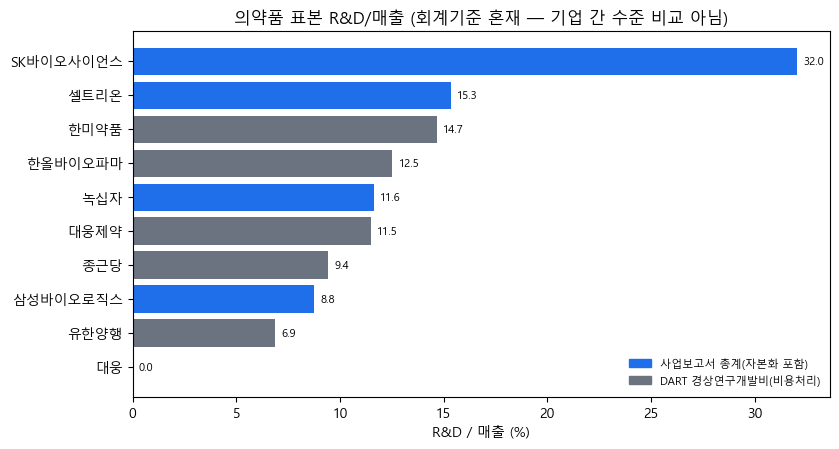

[의약품 R&D/매출] 중앙값(대웅 제외 9개사 기준) 11.6% · 범위 0.01%~32.0%
company_name  rnd_to_sales_pct                     기준
          대웅              0.01 DART 경상연구개발비/매출(비용처리분)
        유한양행              6.88 DART 경상연구개발비/매출(비용처리분)
    삼성바이오로직스              8.77  사업보고서 연구개발비/매출(연결·총계)
         종근당              9.45 DART 경상연구개발비/매출(비용처리분)
        대웅제약             11.48 DART 경상연구개발비/매출(비용처리분)
         녹십자             11.63  사업보고서 연구개발비/매출(연결·총계)
     한올바이오파마             12.53 DART 경상연구개발비/매출(비용처리분)
        한미약품             14.67 DART 경상연구개발비/매출(비용처리분)
        셀트리온             15.34  사업보고서 연구개발비/매출(연결·총계)
   SK바이오사이언스             32.03  사업보고서 연구개발비/매출(연결·총계)


In [7]:
# [셀 7] 의약품 R&D/매출 보조근거 표·그림 — 회계기준별 구분, 배당수익률 축 혼용 제거
SUP = PROCESSED_DIR / "pharma_rnd_support.csv"
if SUP.exists():
    sup = pd.read_csv(SUP).dropna(subset=["rnd_to_sales_pct"]).sort_values("rnd_to_sales_pct")
    is_capitalized = sup["기준"].str.contains("사업보고서")
    colors = np.where(is_capitalized, config.SIGN_COLORS["pos"], "#6b7280")
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    ax.barh(sup["company_name"], sup["rnd_to_sales_pct"], color=colors)
    for y, v in enumerate(sup["rnd_to_sales_pct"]):
        ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=8)
    ax.set_xlabel("R&D / 매출 (%)")
    ax.set_title("의약품 표본 R&D/매출 (회계기준 혼재 — 기업 간 수준 비교 아님)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=config.SIGN_COLORS["pos"], label="사업보고서 총계(자본화 포함)"),
               plt.Rectangle((0, 0), 1, 1, color="#6b7280", label="DART 경상연구개발비(비용처리)")]
    ax.legend(handles=handles, loc="lower right", fontsize=8, frameon=False)
    fig.tight_layout(); fig.savefig(H3_FIGDIR / "pharma_rnd.png", dpi=130, bbox_inches="tight")
    plt.show()
    sup_core = sup[sup["company_name"] != "대웅"]
    print(f"[의약품 R&D/매출] 중앙값(대웅 제외 {len(sup_core)}개사 기준) {sup_core['rnd_to_sales_pct'].median():.1f}% · "
          f"범위 {sup['rnd_to_sales_pct'].min():.2f}%~{sup['rnd_to_sales_pct'].max():.1f}%")
    print(sup[["company_name", "rnd_to_sales_pct", "기준"]].round(2).to_string(index=False))
else:
    print("[SKIP] pharma_rnd_support.csv 없음 — STEP9 R&D 결합 셀 실행 필요")

### 관찰 결과

의약품 10개사의 R&D/매출 비율 중앙값은 약 11.6%이다(10개사 전체 기준). 개별 값의 범위는 최대 SK바이오사이언스 32.0%에서 최소 대웅 0.01%까지 분포한다.

이 분포는 서로 다른 회계 기준의 값이 혼재한 결과다. 삼성바이오로직스, 셀트리온, SK바이오사이언스, 녹십자 4개사는 사업보고서상 연구개발비 총계(자본화분 포함) 기준이고, 한미약품, 한올바이오파마, 대웅제약, 종근당, 유한양행, 대웅 6개사는 DART 경상연구개발비(비용처리분) 기준이다. 두 기준은 분자의 정의가 다르므로 기업 간 수준 비교는 수행하지 않으며, 위 최댓값·최솟값도 기업 간 R&D 강도의 차이로 읽지 않는다.

따라서 이 표는 의약품 표본 다수가 매출 대비 두 자릿수 수준의 연구개발 지출을 보고하고 있다는 사실의 기록에 한정되며, 금리베타와의 관계에 대한 근거로는 사용하지 않는다.


## 의약품 시가총액 집중도

### 목적

- 의약품 산업 10종목의 2024년 시가총액 집중도(Top1·Top3·Top5 비중, HHI)를 계산해, 시총가중 집계(셀 3)가 소수 대형주에 얼마나 좌우되는지 보조적으로 확인한다.
- 다른 6개 산업의 집중도도 함께 계산해, 의약품의 집중도 수준을 상대적으로 판단할 수 있는 비교 기준을 제공한다.
- 7개 산업 순위상관 변수가 아니라 의약품 시총가중 결과 해석의 보조 정황이며, STEP9의 R&D 디스클레이머와 동일한 원칙을 적용한다.


In [8]:
# [셀 8] 의약품 시가총액 집중도 — Top1/3/5 비중 + HHI (+ 7개 산업 비교)
def concentration(g):
    g = g.dropna(subset=["market_cap_2024"]).sort_values("market_cap_2024", ascending=False).reset_index(drop=True)
    total = g["market_cap_2024"].sum()
    g["market_cap_rank"] = g.index + 1
    g["share_pct"] = g["market_cap_2024"] / total * 100
    g["cumulative_share_pct"] = g["share_pct"].cumsum()
    n = len(g)
    hhi = float(((g["market_cap_2024"] / total) ** 2).sum())
    summary = {"top1_share_pct": g["share_pct"].iloc[0] if n >= 1 else np.nan,
               "top3_share_pct": g["share_pct"].iloc[:3].sum() if n >= 3 else np.nan,
               "top5_share_pct": g["share_pct"].iloc[:5].sum() if n >= 5 else np.nan,
               "hhi": hhi, "n_firms": n}
    return g, summary

pharma_conc, pharma_summary = concentration(sel[sel["industry"] == "의약품"][["company_name", "stock_code", "market_cap_2024"]].copy())
pharma_conc.to_csv(H3_TABDIR / "pharma_market_cap_concentration.csv", index=False, encoding="utf-8-sig")
pd.DataFrame([pharma_summary]).to_csv(H3_TABDIR / "pharma_concentration_summary.csv", index=False, encoding="utf-8-sig")

all_rows = []
for ind in INDUSTRIES:
    _, s = concentration(sel[sel["industry"] == ind][["company_name", "stock_code", "market_cap_2024"]].copy())
    s["industry"] = ind
    all_rows.append(s)
comp = pd.DataFrame(all_rows).set_index("industry")[["top1_share_pct", "top3_share_pct", "top5_share_pct", "hhi", "n_firms"]] \
    .sort_values("hhi", ascending=False)
comp.to_csv(H3_TABDIR / "industry_concentration_comparison.csv", encoding="utf-8-sig")

n_ph = pharma_summary["n_firms"]
print(f"[의약품 시총 집중도] n={n_ph} · Top1 {pharma_summary['top1_share_pct']:.1f}% · "
      f"Top3 {pharma_summary['top3_share_pct']:.1f}% · Top5 {pharma_summary['top5_share_pct']:.1f}% · HHI {pharma_summary['hhi']:.3f}")
print(pharma_conc[["company_name", "market_cap_rank", "share_pct", "cumulative_share_pct"]].round(2).to_string(index=False))
print("\n[7개 산업 집중도 비교 — HHI 내림차순]")
print(comp.round(3).to_string())
pharma_rank = int((comp["hhi"] > pharma_summary["hhi"]).sum()) + 1
print(f"\n의약품 HHI 순위: 7개 산업 중 {pharma_rank}위")

[의약품 시총 집중도] n=10 · Top1 50.6% · Top3 88.3% · Top5 94.0% · HHI 0.357
company_name  market_cap_rank  share_pct  cumulative_share_pct
    삼성바이오로직스                1      50.64                 50.64
        셀트리온                2      30.52                 81.15
        유한양행                3       7.19                 88.34
   SK바이오사이언스                4       2.96                 91.30
        한미약품                5       2.69                 93.99
         녹십자                6       1.57                 95.57
     한올바이오파마                7       1.51                 97.08
        대웅제약                8       1.10                 98.18
          대웅                9       0.94                 99.12
         종근당               10       0.88                100.00

[7개 산업 집중도 비교 — HHI 내림차순]
          top1_share_pct  top3_share_pct  top5_share_pct    hhi  n_firms
industry                                                                
의약품               50.639          88.340          93.995  0.357  

### 관찰 결과

의약품 10개사의 2024년 말 시가총액 집중도는 Top1 50.6%(삼성바이오로직스), Top3 88.3%, Top5 94.0%, HHI 0.357이다. 7개 산업 중에서는 전기전자(Top1 53.0%, HHI 0.346)에 이어 두 번째로 높으나 전기전자와 사실상 같은 수준이며, 의약품 표본에만 특이하게 나타나는 구조는 아니다.

다만 의약품의 시가총액가중 배당수익률 0.139%는 삼성바이오로직스(무배당)와 셀트리온(10개년 중 대부분 무배당)의 높은 시가총액 비중에 크게 좌우된다. 현재 자료만으로 두 기업의 낮은 배당을 현금흐름 듀레이션에만 귀속할 수는 없으며, 기업별 배당정책이나 사업단계 등 다른 요인과도 양립 가능한 관측으로 해석한다.

중앙값 기준(0.360%)에서도 의약품은 7개 산업 중 최저를 유지하므로, 배당수익률 순위상의 방향성 자체는 집계 기준을 바꾸어도 유지된다. 반면 앞 절에서 확인된 바와 같이 중앙값 기준의 순위상관은 유의수준에 도달하지 않으며, 의약품 제외 시 크게 낮아진다.


## 해석

### 이 절이 대상으로 하는 대비

Baseline의 산업 간 공동검정은 귀무가설을 기각하지만(F=4.269, p=0.000264), 그 차이는 쌍별 수준에서 의약품이 포함된 6쌍에만 BH 보정 후 나타나고 비의약품 15쌍에서는 나타나지 않는다. 따라서 이 절의 순위상관은 "7개 산업의 금리베타 서열 전반"이 아니라 "의약품이 만든 대비"가 재무특성 순위와 어느 방향으로 정렬되는지를 보조적으로 살펴보는 성격을 가진다.

### 데이터가 직접 보여주는 것 (A)

- 의약품의 Baseline 금리베타는 -0.0271이며 BH 보정 후 유의하다(BH p=0.0038). 7개 산업 중 유일한 음(-) 계수다.
- 금융업(0.0112), 운수장비(0.0172), 철강금속(0.0188)은 유의한 양(+) 계수이고, 건설업(0.0032), 화학(0.0026), 전기전자(0.0016)는 유의수준에 도달하지 않는다.
- 의약품은 부채비율(시총가중 0.493, 중앙값 0.628)과 배당수익률(시총가중 0.139%, 중앙값 0.360%)이 7개 산업 중 최저다.
- 배당수익률과 금리베타의 산업 순위상관은 시가총액가중 기준 rho=0.857(순열 p=0.0238), 중앙값 기준 rho=0.536(p=0.2357)이다.
- 의약품 10개사의 R&D/매출 중앙값은 11.6%이며, 자본화 4개사와 비용처리 6개사의 기준이 혼재한다.
- 의약품의 시가총액 집중도는 HHI 0.357로 전기전자(0.346)와 유사한 수준이고, 시총가중 배당수익률은 삼성바이오로직스·셀트리온의 가중치에 의해 대부분 결정된다.

### 경제적 해석과 정합적인 것 (B)

- 의약품에서 낮은 배당수익률(두 집계 기준 모두 최저)과 R&D 지출이 함께 관측된다는 사실은, 현재 현금흐름보다 미래 성장 기대의 비중이 큰 기업에 관한 이론적 서술과 모순되지 않는다. 다만 본 자료는 이익유보율이나 전체 재투자 비중을 직접 측정하지 않았으므로 그 수준 자체를 확인한 것은 아니다.
- 그러한 특성을 가진 자산의 현재가치가 할인율 변화에 상대적으로 크게 반응한다는 장기 현금흐름·듀레이션 논리는, 의약품이 유일한 유의한 음(-) 금리베타를 갖는다는 관측과 정합적일 가능성이 있다.
- 배당수익률과 금리베타의 양(+) 순위 정렬은, 배당수익률이 높은 금융업(3.76%)·철강금속(2.76%)이 유의한 양(+) 계수를 보인다는 사실과도 같은 방향이다. 이 방향은 고배당 산업이 금리 상승 국면에서 더 부진해야 한다는 형태의 서술과는 반대이므로, 그러한 서술은 본 표본에서 지지되지 않는다.
- leave-one-out에서 의약품을 제외해도 시가총액가중 배당-베타 상관의 부호와 크기가 유지되는 점(rho=0.771)은, 이 정렬이 의약품 단일 산업만으로 형성된 것은 아니라는 해석과 정합적이다.

### 아직 입증되지 않은 것 (C)

- 의약품의 음(-) 금리베타가 긴 현금흐름 듀레이션에서 비롯되었다는 진술은 본 분석에서 검정되지 않았다.
- R&D 지출이 금리베타를 형성하는 경로에 있다는 진술은 검정되지 않았다. R&D 자료는 의약품 표본에 대해서만 수집되었고 회계 기준이 혼재하므로, 기업 간·산업 간 비교의 근거로 사용할 수 없다.
- 배당수익률이 실제 현금흐름 듀레이션을 측정한다는 전제는 확인되지 않았다. 의약품의 시총가중 배당수익률은 삼성바이오로직스·셀트리온의 높은 시가총액 비중에 크게 좌우되며, 현재 자료만으로 기업별 배당정책·사업단계와 듀레이션 관련 요인을 분리할 수 없다.
- 산업 단위 n=7 순위상관은 인과적 방향을 식별하지 않으며, 산업 구성·규모·글로벌 수요 노출 등 관측되지 않은 공통 요인과 구분되지 않는다.

### 만기 구조 및 수익률곡선 요인 결과와의 대조

의약품에 대한 만기별·수익률곡선 요인별 추정 결과는 다음과 같다.

| 설명변수 | 계수 | p |
|---|---|---|
| 국고 3년 | -0.02707 | 0.000548 |
| 국고 10년 | -0.01598 | 0.0697 |
| NS Level | -0.01382 | 0.383 |
| NS Slope | -0.00901 | 0.534 |
| NS Curvature | -0.00860 | 0.00236 |

장기 현금흐름 듀레이션을 중심으로 한 해석에서는 장기 금리 및 수준(Level) 요인에 대한 음(-) 반응이 가장 뚜렷하게 나타나는 형태를 예상할 수 있으나, 본 표본에서는 단기 구간(3년) 계수의 절댓값이 더 크고 10년 계수는 유의수준에 도달하지 않으며, Level 요인은 유의수준에 도달하지 않고 중기 구간에 대응하는 Curvature 요인만 유의하다. 다만 3년 계수와 10년 계수의 차이 자체는 별도로 검정되지 않았고 두 만기 금리 변화는 상관이 높으므로, 이 결과를 듀레이션 해석의 기각으로 읽을 수는 없다. 정확한 서술은 계수 간 차이가 직접 검정되지 않았으며, 관측된 만기별 노출 패턴이 단순한 장기 듀레이션 해석과 곧바로 정합하지는 않는다는 것이다.

### 배당수익률 결과의 강건성 제약

시가총액가중 배당-베타 상관의 유의 판정은 결측 처리 규칙과 표본 구성에 민감하다. 배당 미공시 연도를 무배당 0으로 계상하는 현행 처리에서는 rho=0.857(p=0.0238)이나, 결측으로 제외하는 대안 처리에서는 rho=0.7857로 n=7 임계값과 정확히 일치한다(p=0.0480). leave-one-out에서는 부호가 7개 경우 모두 양(+)으로 유지되지만 5% 수준 도달 여부는 제외 산업에 따라 갈리며, 중앙값 기준에서는 의약품 제외 시 rho가 0.536에서 0.257로 낮아진다. 따라서 이 결과는 확정적 근거가 아니라 탐색적으로 정합적인 관측으로 취급한다.

### 부채비율의 위치

부채비율은 어떤 집계 기준에서도 5% 수준에 도달하지 않고(시총가중 rho=0.607, 중앙값 rho=0.750, 금융업 제외 6산업 rho=0.657), 공통기간(2023~2025년)으로 맞추어도 개선되지 않으며(시총가중은 사실상 불변, 중앙값은 오히려 하락), 철강금속 1개 산업 제외만으로 판정이 뒤집힌다(0.607 → 0.943). 금융업 부채비율의 자료 공백은 사업보고서 원문 재수집으로 100 firm-year 중 43건에서 97건 확보로 개선되었으나 (잔여 결측 3건은 우리금융지주가 2019년 신설되어 그 이전 사업보고서가 존재하지 않는 구조적 사유), 위 순위상관 결과는 자료 완전성과 무관하게 복구 전후로 동일하다. 따라서 부채비율 결과의 불안정성을 단순한 자료 공백만으로 설명하기는 어렵다. 산업 수 n=7의 소표본, 산업 하나의 순위 이동에 대한 민감성, 그리고 예금·보험부채로 인해 금융업 부채비율의 경제적 의미가 다른 점이 함께 제한요인으로 남는다. 이에 부채비율은 결론 산출에 사용하지 않고 탐색적 병기 변수로만 제시한다.


## STEP10 요약

**1. 이 절이 다루는 대비의 범위.** Baseline의 산업 간 공동검정은 유의하지만(F=4.269, df=(6, 17136), p=0.000264), BH 보정 후 유의한 쌍은 21쌍 중 6쌍이며 모두 의약품을 포함한다. 비의약품 15쌍은 모두 비유의하다(최소 BH p=0.100). 이 절의 재무특성 순위 분석은 그 대비를 보조적으로 재확인하는 탐색적 성격을 갖는다.

**2. 배당수익률과의 정렬.** 산업 단위 순위상관은 시가총액가중 기준 rho=0.857(순열 p=0.0238), 중앙값 기준 rho=0.536(p=0.2357)으로 양(+) 방향이다. 그러나 결측 처리 대안에서 rho=0.7857로 n=7 임계값과 정확히 일치하고(p=0.0480), leave-one-out에서 부호는 유지되되 유의 판정은 제외 산업에 따라 갈린다. 의약품을 제외해도 시가총액가중 상관의 부호·크기는 유지된다(rho=0.771). 이 결과는 확정적 근거가 아니라 탐색적으로 정합적인 관측 수준으로 제한한다.

**3. 부채비율.** 어떤 집계 기준·기간 조정에서도 5% 수준에 도달하지 않고, 철강금속 1개 산업 제외만으로 rho가 0.607에서 0.943으로 이동한다. 금융업은 API의 XBRL 자료 공백(8개 실제 금융회사 2016~2022년)을 사업보고서 원문 재수집으로 보완해 100 firm-year 중 확보율이 43건에서 97건으로 개선되었으나(잔여 3건은 우리금융지주가 2019년 신설되어 그 이전 사업보고서가 존재하지 않는 구조적 결측), 순위상관 결과 자체는 복구 전후로 변화가 없다. 따라서 결과의 불안정성을 단순한 자료 공백만으로 설명하기는 어렵고, n=7 소표본과 산업별 측정·경제적 의미의 이질성이 함께 제한요인으로 남는다. 금융업 부채비율은 예금·보험부채 비중이 커 제조업의 차입 부담과도 의미가 다르다. 부채비율은 결론 산출에 사용하지 않고 탐색적 병기 변수로 제시한다.

**4. 의약품에 대한 3분할 정리.**
- (A) 데이터가 직접 보여주는 것: 의약품 β=-0.0271(BH p=0.0038, 7개 산업 중 유일한 음(-) 계수), 부채비율(0.493/0.628)과 배당수익률(0.139%/0.360%) 모두 최저, R&D/매출 중앙값 11.6%, 시가총액 집중도 HHI 0.357.
- (B) 경제적 해석과 정합적인 것: 낮은 현재 배당과 R&D 지출이 함께 관측되는 상태는 미래 성장 기대 중심의 가치 구성에 관한 이론적 서술과 모순되지 않으며, 장기 현금흐름·듀레이션 논리와 정합적일 가능성이 있다. 다만 전체 재투자 비중을 직접 측정한 것은 아니다.
- (C) 아직 입증되지 않은 것: 음(-) 금리베타가 긴 듀레이션에서 비롯되었다는 것, R&D 지출이 금리베타를 형성하는 경로에 있다는 것, 배당수익률이 실제 현금흐름 듀레이션을 측정한다는 것. 세 가지 모두 본 분석에서 검정되지 않았다.

**5. 반대 방향 증거.** 의약품의 만기별 노출은 3년 금리 계수 -0.02707(p=0.000548, 유의)이 10년 금리 계수 -0.01598(p=0.0697, 비유의)보다 절댓값이 크고, NS Level -0.01382(p=0.383)와 NS Slope -0.00901(p=0.534)은 유의수준에 도달하지 않으며 NS Curvature -0.00860(p=0.00236)만 유의하다. 3년·10년 계수의 차이는 직접 검정되지 않았고 두 만기 금리 변화의 상관이 높으므로 듀레이션 해석의 기각으로 읽지 않되, 관측된 만기별 노출 패턴이 단순한 장기 듀레이션 해석과 곧바로 정합하지는 않는다.

**6. 표본 구성 관련 유보.** 의약품의 시가총액 집중도(HHI 0.357)는 전기전자(0.346)와 유사한 수준이므로 의약품 표본만 특이한 구조는 아니다. 다만 시총가중 배당수익률 0.139%는 삼성바이오로직스·셀트리온의 높은 시가총액 비중에 크게 좌우된다. 현재 자료만으로 두 기업의 낮은 배당을 듀레이션에만 귀속하거나 기업 생애주기와 분리해 해석할 수는 없다. 중앙값 기준에서도 최저가 유지되어 방향성 자체는 집계 기준에 따라 뒤집히지 않는다.

**Takeaway.** Baseline의 쌍별 차이는 의약품이 포함된 6쌍에 집중되어 있는 반면, 시가총액가중 배당수익률과 금리베타의 양(+) 순위 정렬은 의약품을 제외한 경우에도 방향과 크기가 유지된다(rho=0.771). 따라서 Baseline의 의약품 중심 대비와 배당-베타 순위 정렬을 동일한 현상으로 간주하지 않는다. 의약품의 낮은 배당수익률과 R&D 지출은 장기 현금흐름·듀레이션에 관한 이론적 해석과 모순되지 않지만, 유의 판정이 결측 처리와 표본 구성에 민감하고 만기별 노출 패턴도 단순한 장기 듀레이션 서사와 곧바로 정합하지 않는다. 부채비율에서도 안정적인 정렬이 관측되지 않으므로, 현 단계의 H3 결과는 재무특성이 산업별 금리베타 차이를 설명한다는 결론이 아니라 가능한 해석을 탐색적으로 제시하는 수준으로 제한한다.

- 상세 내용: `results/H3_firm_characteristics/summary.md`
